# Through-glass transmission reconstruction


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`observation`，shape `(1, 1080, 1440, 3)`，dtype `<f8`：Real normalized JPEG intensity, dimensionless relative detector units; axes batch, native row, native column, RGB.。未知量为1080×1440×3均值保持的transmission-like场。

获取模型：玻璃透射层与模糊反射层混合形成JPEG图，mixing/PSF和常数层不唯一。

如何恢复：src.solvers.reconstruct：强梯度阈值、带小screen项的Poisson/DCT恢复。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell3照片；5梯度；7主动；9三图原方法/新场；11阈值；12epsilon；14已知合成层失败模式；16额外真实场景；17加噪。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留9个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。仅conditional transmission-like场，不是唯一两层/绝对辐亮度；额外synthetic case有真层，主真实样本没有GT。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

A single train-window photograph combines a desired landscape and unwanted interior reflections. Recover the complete transmission-like image under the selected published inverse's mean convention. This is a conditional reflection-suppression inverse: **no independent true transmission layer exists for this real image**. We will not relabel an original reconstruction as physical truth.

All fresh images below are computed through local src mathematics. The full1080×1440RGB grid is preserved. Original/default numerical comparisons, real-image limitations, independent known-layer synthetic cases and source-paper historical comparisons have separate roles.

In [1]:
%matplotlib inline
from pathlib import Path
import os,sys,json,time,subprocess,gc
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'data/raw_data.npz').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observation
from src.physics_model import gradient,divergence,laplacian,threshold_gradients,stationarity
from src.solvers import reconstruct
from src.main import run
from src.generate_data import synthetic_mixture,perturb_observation
from src.visualization import image_grid,scientific_style
scientific_style();started=time.perf_counter();REF=ROOT/'notebooks/reference_outputs'
export=Path(os.environ.get('IMAGING_REVIEW_EXPORT',str(next(parent for parent in ROOT.parents if parent.name == 'tasks').parent.parent/'imaging-101-maintainer/review_exports'/ROOT.name)));export.mkdir(parents=True,exist_ok=True)
original_show=plt.show;figure_counter=0
def review_show(*args,**kwargs):
    global figure_counter
    for number in plt.get_fignums():
        figure_counter+=1;fig=plt.figure(number)
        for suffix in ('png','svg','pdf'):fig.savefig(export/f'figure_{figure_counter:02d}.{suffix}',bbox_inches='tight')
    output=original_show(*args,**kwargs);plt.close('all');gc.collect();return output
plt.show=review_show
y=load_observation(ROOT/'data/raw_data.npz')
with np.load(REF/'upstream.npz',allow_pickle=False) as z:original=z['reconstruction'][0]
print('Full native RGB observation:',y.shape,'float64 range:',float(y.min()),float(y.max()))
print('Execution backend:',sys.executable,'NumPy',np.__version__)
assert y.shape==(1080,1440,3)

Full native RGB observation: (1080, 1440, 3) float64 range: 0.0 1.0
Execution backend: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy 2.4.6


## 2. Data

The benchmark reuses train2.jpg, the exact real photograph in the author's sample command and paper's opening train-window example. Its8-bit JPEG values are divided by255. No crop, resizing, gamma inversion, denoising or target-derived calibration is applied. Focal geometry, mixing fraction, reflection blur and measured noise variance are unavailable. Values are relative encoded intensity, not calibrated scene radiance.

Three additional real repository examples are used later for transfer/failure inspection. Repository inclusion does not establish their capture ownership; the supplementary paper also uses Internet examples. None of those scenes replaces the bound image after inspecting results.

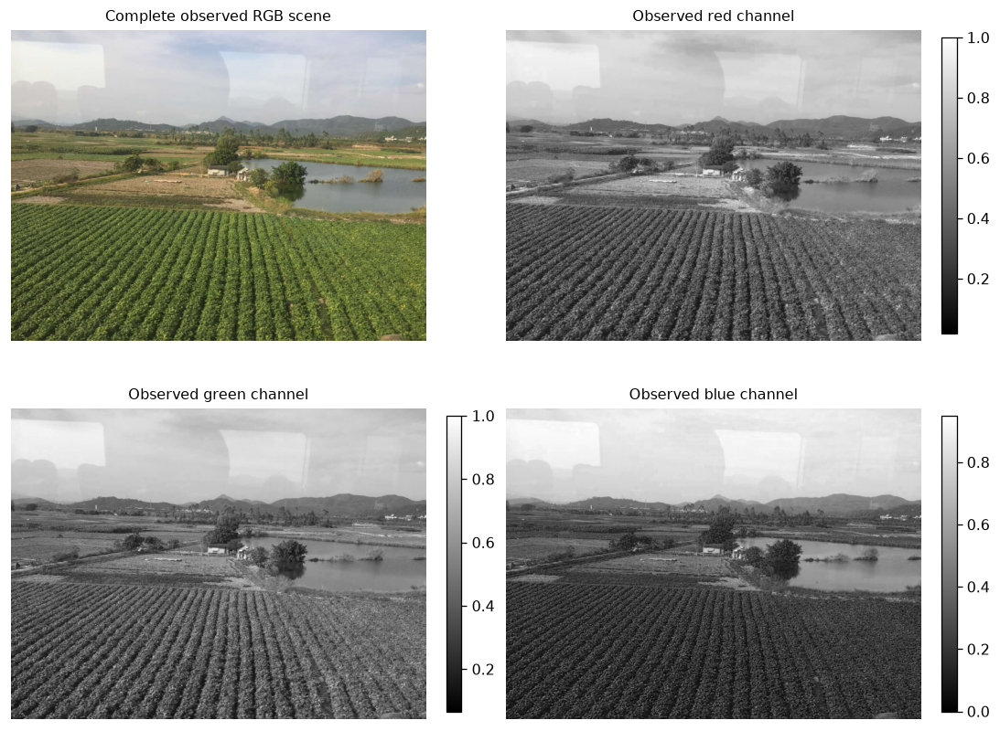

All 4665600 channel samples retained; native rows downward, columns rightward.


In [2]:
image_grid([y,y[...,0],y[...,1],y[...,2]],['Complete observed RGB scene','Observed red channel','Observed green channel','Observed blue channel'],columns=2);plt.show()
print('All',y.size,'channel samples retained; native rows downward, columns rightward.')

## 3. Physics

An approximate image-domain model is

$$Y_c=aT_c+(1-a)(G_s*R_c)+n_c.$$

Y is observed intensity, T transmission, R reflection, a an unknown mixing fraction, G a normalized blur kernel of width s, n mismatch/noise, and c a color channel. The star is spatial convolution. A focused transmitted scene often has stronger edges than a blurred reflection; sharp reflections and weak transmission details violate this cue.

A single view cannot separate constant components. The selected inverse keeps each observed channel mean; it does not discover the true reflection offset. Its native forward spatial differences have zero outgoing flux, giving a nonperiodic Neumann Laplacian L=div∇.

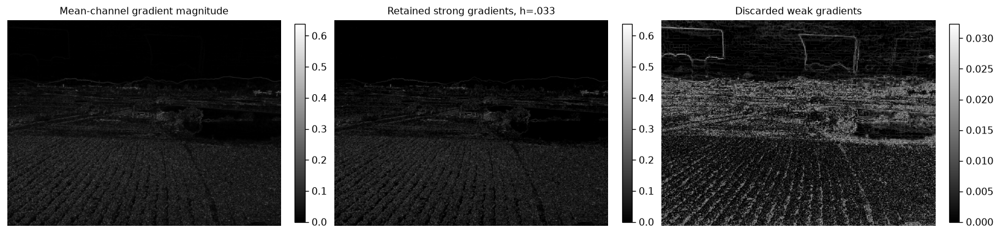

Retained gradient fractions R/G/B [0.4593717849794239, 0.45865612139917694, 0.4577591306584362]


11728

In [3]:
g=gradient(y);kept=threshold_gradients(y,.033);gmag=np.sqrt(np.sum(g*g,axis=-1));keptmag=np.sqrt(np.sum(kept*kept,axis=-1))
image_grid([gmag.mean(axis=2),keptmag.mean(axis=2),(gmag-keptmag).mean(axis=2)],['Mean-channel gradient magnitude','Retained strong gradients, h=.033','Discarded weak gradients'],columns=3);plt.show()
retained_fraction=[float(np.mean(gmag[...,c]>.033)) for c in range(3)]
print('Retained gradient fractions R/G/B',retained_fraction)
np.savez_compressed(export/'gradient_diagnostics.npz',magnitude=gmag,retained_magnitude=keptmag)
del g,kept,gmag,keptmag;gc.collect()

## 4. Method

Let δ retain a pixel's two gradient components only when their channelwise magnitude is **strictly greater** than h=.033. The original MATLAB hard-threshold API uses this strict rule; paper Eq5 prints ≥, so ties follow executable/API evidence rather than silently changing the method. Set f=div(δ∇Y). The convex objective is

$$\Phi(X)=\tfrac12\lVert LX-f\rVert_F^2+\tfrac{\varepsilon}{2}\lVert X-Y\rVert_F^2,$$

where X is the output, ε=1e-8 and the Frobenius norm includes every image position. Its unique stationary solution satisfies

$$(L^2+\varepsilon\mathrm{Id})X=Lf+\varepsilon Y.$$

The local code explicitly implements gradients, threshold, divergence, boundary conventions and right-hand side. It evaluates the inverse with a generic cosine transform and explicit Neumann eigenvalues; there is no hidden domain solver or artificial iteration. Negative and above-one numerical values are retained in saved arrays. RGB display alone clips to[0,1] with exact overflow counts.

In [4]:
t=time.perf_counter();fresh=run(ROOT);primary_seconds=time.perf_counter()-t
command=[sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')]
p=subprocess.run(command,cwd=ROOT,capture_output=True,text=True);assert p.returncode==0,p.stdout+p.stderr
report=json.loads((ROOT/'output/judge_report.json').read_text(encoding='utf8'))
print('Full active reconstruction+NPZ I/O seconds:',primary_seconds);print('Unclipped range:',float(fresh.min()),float(fresh.max()))
print('Independent standalone Judge:',json.dumps(report,indent=2))
assert report['passed']

Full active reconstruction+NPZ I/O seconds: 2.5231244000024162
Unclipped range: -0.02137112067422501 1.0773757632414849
Independent standalone Judge: {
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.000000000000006,
    "nrmse": 1.3890866529870287e-10,
    "maximum_absolute": 4.598692537882698e-10,
    "stationarity_relative": 5.067320257622532e-15,
    "channel_mean_absolute": 1.8149759473118365e-10
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.9999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "maximum_absolute": {
      "comparison": "<=",
      "boundary": 5e-07
    },
    "stationarity_relative": {
      "comparison": "<=",
      "boundary": 1e-08
    },
    "channel_mean_absolute": {
      "comparison": "<=",
      "boundary": 1e-06
    }
  },
  "errors": []
}


## 5. Results

The original reference below was actually executed on this exact photograph with unchanged reflectSuppress.m. Octave's missing general wthresh primitive was supplied by a documented strict-threshold API shim. Source stages were captured independently before local implementation; the instrumented source produced the same complete result bitwise. This establishes numerical reproduction, not real-image layer accuracy.

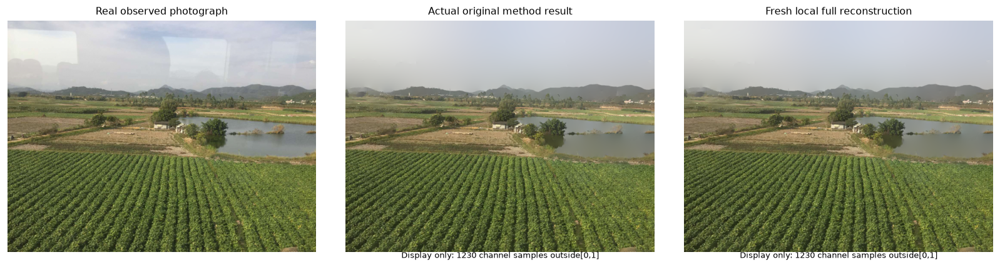

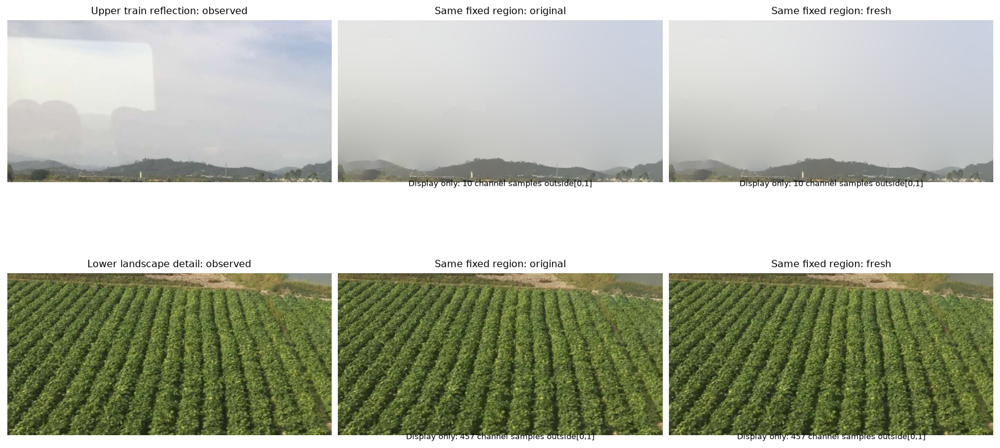

Regions are display-only fixed image coordinates. Every inverse and metric uses the complete native grid.


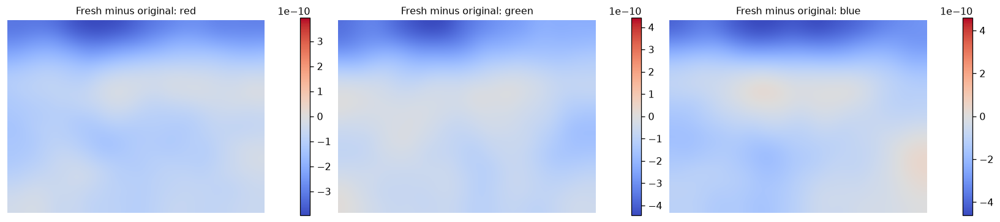

Full maximum source discrepancy: 4.598692537882698e-10
Per-channel original/fresh means: [0.51948675 0.53726848 0.43132525] [0.51948675 0.53726848 0.43132525]
Out-of-range samples retained: 1230


In [5]:
image_grid([y,original,fresh],['Real observed photograph','Actual original method result','Fresh local full reconstruction'],columns=3);plt.show()
regions=[('Upper train reflection',slice(0,360),slice(0,720)),('Lower landscape detail',slice(600,960),slice(360,1080))]
region_arrays=[];region_titles=[]
for label,rows,cols in regions:
    region_arrays += [y[rows,cols],original[rows,cols],fresh[rows,cols]]
    region_titles += [label+': observed','Same fixed region: original','Same fixed region: fresh']
image_grid(region_arrays,region_titles,columns=3);plt.show()
print('Regions are display-only fixed image coordinates. Every inverse and metric uses the complete native grid.')
delta=fresh-original
image_grid([delta[...,c] for c in range(3)],['Fresh minus original: red','Fresh minus original: green','Fresh minus original: blue'],columns=3,signed=True);plt.show()
print('Full maximum source discrepancy:',float(np.max(abs(delta))))
print('Per-channel original/fresh means:',original.mean(axis=(0,1)),fresh.mean(axis=(0,1)))
print('Out-of-range samples retained:',int(np.count_nonzero((fresh<0)|(fresh>1))))

Increasing h trades reflection suppression against true scene detail. The following five images and diagnostics are recomputed at fixed, predeclared thresholds. No independently unknown transmission is used to choose h. Parameter0.033 remains the benchmark setting.

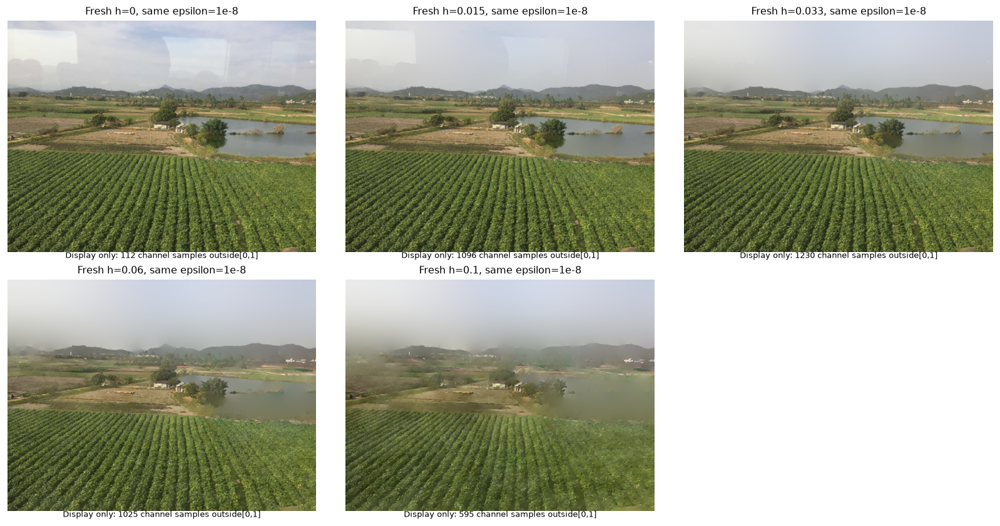

[
  {
    "h": 0.0,
    "relative_change_from_observation": 4.507600640916152e-10,
    "stationarity": 5.147179921329791e-15,
    "additional_reconstruction_seconds": 0.6939591999980621,
    "runtime_role": "pure reconstruction, excludes NPZ I/O",
    "outside01_count": 112
  },
  {
    "h": 0.015,
    "relative_change_from_observation": 0.032226068338494965,
    "stationarity": 5.126591886434448e-15,
    "additional_reconstruction_seconds": 0.6976230000000214,
    "runtime_role": "pure reconstruction, excludes NPZ I/O",
    "outside01_count": 1096
  },
  {
    "h": 0.033,
    "relative_change_from_observation": 0.0553735023841153,
    "stationarity": 5.066400130177316e-15,
    "additional_reconstruction_seconds": null,
    "runtime_role": "reused actively computed primary; not timed again",
    "outside01_count": 1230
  },
  {
    "h": 0.06,
    "relative_change_from_observation": 0.08394081617182957,
    "stationarity": 5.039927998342933e-15,
    "additional_reconstruction_seconds": 

10720

In [6]:
thresholds=[0.,.015,.033,.06,.1];h_results=[];h_facts=[]
for h in thresholds:
    t=time.perf_counter();out=fresh if h==.033 else reconstruct(y,h=h);seconds=time.perf_counter()-t
    h_results.append(out);h_facts.append({'h':h,'relative_change_from_observation':float(np.linalg.norm(out-y)/np.linalg.norm(y)),'stationarity':stationarity(y,out,h=h),'additional_reconstruction_seconds':None if h==.033 else seconds,'runtime_role':'reused actively computed primary; not timed again' if h==.033 else 'pure reconstruction, excludes NPZ I/O','outside01_count':int(np.count_nonzero((out<0)|(out>1)))})
image_grid(h_results,[f'Fresh h={h:g}, same epsilon=1e-8' for h in thresholds],columns=3);plt.show()
np.savez_compressed(export/'threshold_fields.npz',**{f'h_{i}':out[None] for i,out in enumerate(h_results)})
print(json.dumps(h_facts,indent=2));del h_results;gc.collect()

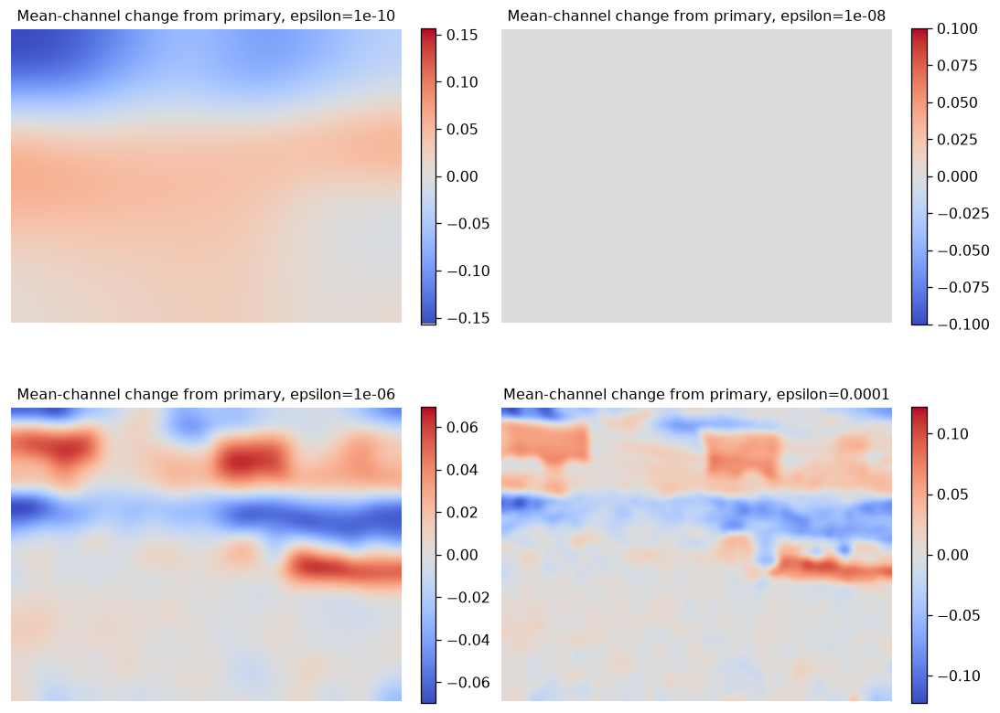

Smaller epsilon is a more ill-conditioned contextual experiment, not a changed primary criterion.
[
  {
    "epsilon": 1e-10,
    "source_max_absolute": 6.164500021554886e-09,
    "channel_mean_error": 2.012605193613126e-09,
    "stationarity": 5.18201676134207e-15
  },
  {
    "epsilon": 1e-08,
    "source_max_absolute": 4.598692537882698e-10,
    "channel_mean_error": 1.8149759473118365e-10,
    "stationarity": 5.066400130177316e-15
  },
  {
    "epsilon": 1e-06,
    "source_max_absolute": 9.573897230552575e-12,
    "channel_mean_error": 2.2304380564719395e-13,
    "stationarity": 5.1001306553990194e-15
  },
  {
    "epsilon": 0.0001,
    "source_max_absolute": 1.609823385706477e-13,
    "channel_mean_error": 2.481348460037225e-14,
    "stationarity": 5.256542893858847e-15
  }
]


15760

In [7]:
epsilons=[1e-10,1e-8,1e-6,1e-4];epsilon_facts=[];epsilon_maps=[]
with np.load(ROOT/'test/fixtures/controls.npz',allow_pickle=False) as z:
    for i,epsilon in enumerate(epsilons):
        out=fresh if epsilon==1e-8 else reconstruct(y,epsilon=epsilon)
        upstream=z[f'e{i}'];epsilon_facts.append({'epsilon':epsilon,'source_max_absolute':float(np.max(abs(out-upstream))),'channel_mean_error':float(np.max(abs(out.mean(axis=(0,1))-y.mean(axis=(0,1))))),'stationarity':stationarity(y,out,epsilon=epsilon)})
        epsilon_maps.append((out-fresh).mean(axis=2))
image_grid(epsilon_maps,[f'Mean-channel change from primary, epsilon={e:g}' for e in epsilons],columns=2,signed=True);plt.show()
print('Smaller epsilon is a more ill-conditioned contextual experiment, not a changed primary criterion.');print(json.dumps(epsilon_facts,indent=2))
del epsilon_maps,out,upstream;gc.collect()

Known-layer synthetic cases make the physical limitation testable. The generated transmission and reflected layer are **not real-scene truth**. The acquisition uses an explicit normalized Gaussian PSF and known mixing fraction. We show both the actual transmitted component and the mean-convention target; adding the known reflection mean is only an evaluation explanation of the chosen constant component, never an input to reconstruction. Weak transmitted edges may be suppressed even when the convex equation is solved accurately.

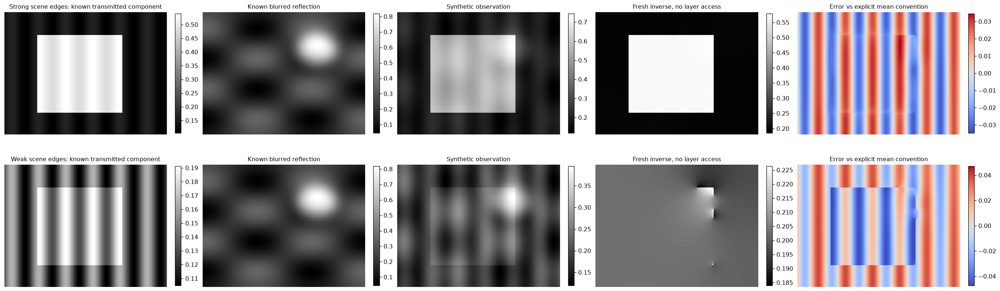

[
  {
    "case": "Strong scene edges",
    "gradient_relative_l2": 0.11181677950781345,
    "mean_convention_rmse": 0.02096156529121688,
    "absolute_transmitted_component_rmse": 0.061541209766477235
  },
  {
    "case": "Weak scene edges",
    "gradient_relative_l2": 0.9805447724783908,
    "mean_convention_rmse": 0.024189104940284305,
    "absolute_transmitted_component_rmse": 0.06271400234585635
  }
]


38953

In [8]:
synthetic_facts=[];synthetic_images=[];synthetic_titles=[];synthetic_arrays={}
for tag,weak in [('Strong scene edges',False),('Weak scene edges',True)]:
    z=synthetic_mixture(weak=weak,noise=0);out=reconstruct(z['observation']);target=z['mean_convention_target']
    relative_gradient_error=float(np.linalg.norm(gradient(out)-gradient(target))/np.linalg.norm(gradient(target)))
    synthetic_facts.append({'case':tag,'gradient_relative_l2':relative_gradient_error,'mean_convention_rmse':float(np.sqrt(np.mean((out-target)**2))),'absolute_transmitted_component_rmse':float(np.sqrt(np.mean((out-z['transmitted_component'])**2)))})
    synthetic_images += [z['transmitted_component'],z['blurred_reflection'],z['observation'],out,out-target]
    synthetic_titles += [tag+': known transmitted component','Known blurred reflection','Synthetic observation','Fresh inverse, no layer access','Error vs explicit mean convention']
    for key in ('observation','transmitted_component','blurred_reflection','mean_convention_target'):synthetic_arrays[f'{weak}_{key}']=z[key]
    synthetic_arrays[f'{weak}_fresh']=out
image_grid(synthetic_images,synthetic_titles,columns=5,signed=[4,9]);plt.show();print(json.dumps(synthetic_facts,indent=2))
np.savez_compressed(export/'synthetic_known_layers.npz',**synthetic_arrays)
del synthetic_images,synthetic_arrays;gc.collect()

The next three full native real scenes were selected before their original source runs. Each source and fresh result uses the same threshold0.033, without choosing settings from an unavailable true layer. The examples can retain sharp reflections or remove desired detail. Their inclusion illustrates transfer and failure rather than a claim of measured accuracy or uniform visual improvement.

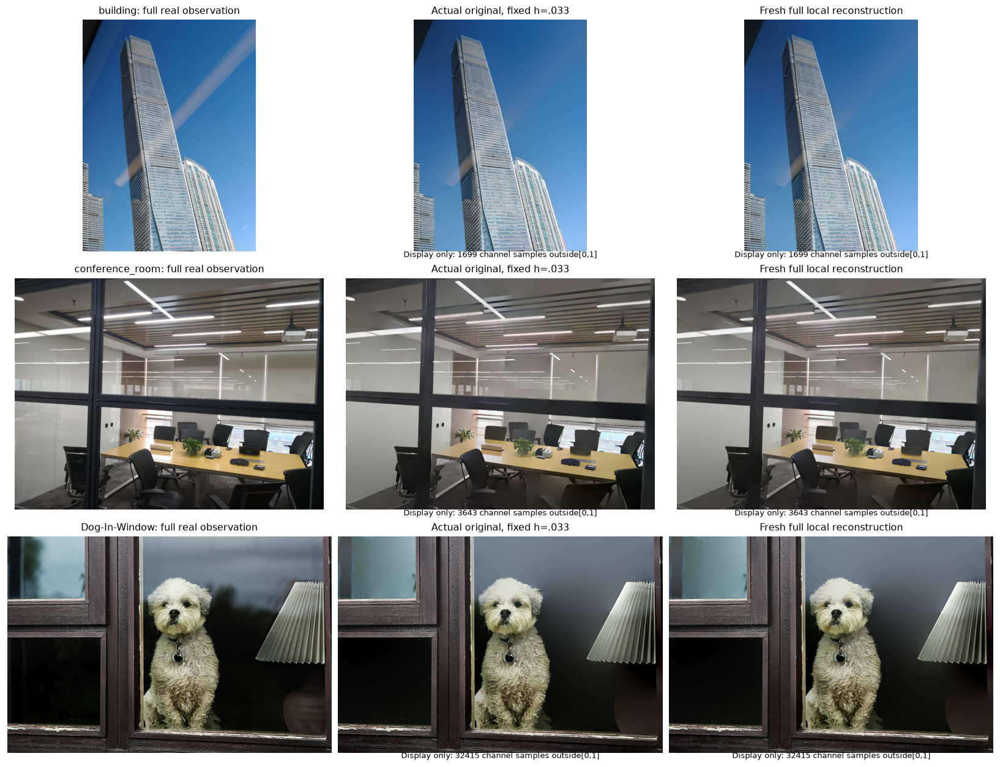

{
  "building": {
    "native_shape": [
      1440,
      1080,
      3
    ],
    "seconds": 0.7025412999937544,
    "source_max_absolute": 3.023644667976555e-10,
    "stationarity": 7.192631620415914e-15,
    "output_range": [
      -0.045585139485330474,
      1.0432145971203537
    ]
  },
  "conference_room": {
    "native_shape": [
      1080,
      1440,
      3
    ],
    "seconds": 0.6926524000009522,
    "source_max_absolute": 1.8636198140242755e-10,
    "stationarity": 1.0053959488761132e-14,
    "output_range": [
      -0.10247117765534805,
      1.0592357204436684
    ]
  },
  "Dog-In-Window": {
    "native_shape": [
      667,
      1000,
      3
    ],
    "seconds": 0.2760095999983605,
    "source_max_absolute": 3.843503848521834e-10,
    "stationarity": 3.723453744359103e-15,
    "output_range": [
      -0.2867224393922414,
      1.1351438448692943
    ]
  }
}


17521

In [9]:
scene_images=[];scene_titles=[];scene_facts={}
for name in ['building','conference_room','Dog-In-Window']:
    with np.load(REF/(name+'.npz'),allow_pickle=False) as z:observation=z['observation'][0];upstream=z['source_reconstruction'][0]
    t=time.perf_counter();out=reconstruct(observation);seconds=time.perf_counter()-t
    scene_images += [observation,upstream,out];scene_titles += [name+': full real observation','Actual original, fixed h=.033','Fresh full local reconstruction']
    scene_facts[name]={'native_shape':list(observation.shape),'seconds':seconds,'source_max_absolute':float(np.max(abs(out-upstream))),'stationarity':stationarity(observation,out),'output_range':[float(out.min()),float(out.max())]}
    np.savez_compressed(export/(name+'_fresh.npz'),reconstruction=out[None])
image_grid(scene_images,scene_titles,columns=3);plt.show();print(json.dumps(scene_facts,indent=2))
del scene_images,observation,upstream,out;gc.collect()

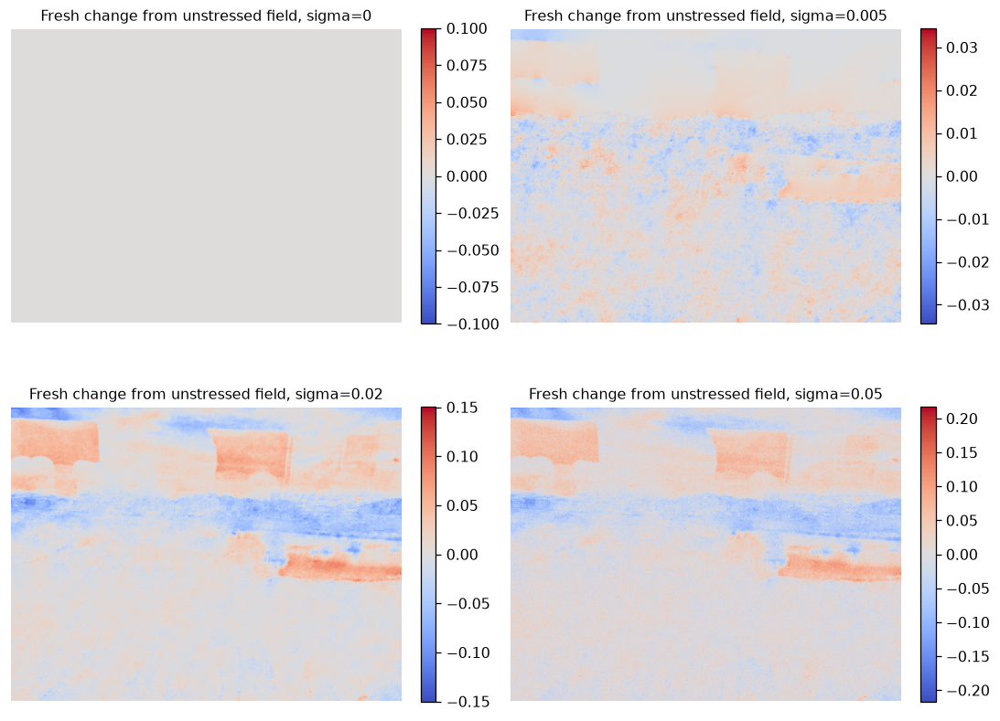

Illustrative Gaussian detector-unit stress, not measured camera noise; no clipping of scientific arrays.
[
  {
    "sigma": 0.0,
    "relative_field_change": 0.0,
    "same_observation_stationarity": 5.066400130177316e-15
  },
  {
    "sigma": 0.005,
    "relative_field_change": 0.012021045019452987,
    "same_observation_stationarity": 4.86493672802602e-15
  },
  {
    "sigma": 0.02,
    "relative_field_change": 0.058797431663391936,
    "same_observation_stationarity": 2.8209455361834304e-15
  },
  {
    "sigma": 0.05,
    "relative_field_change": 0.10621784921281197,
    "same_observation_stationarity": 1.404787930606884e-15
  }
]


16092

In [10]:
sigmas=[0.,.005,.02,.05];noise_facts=[];noise_images=[]
for sigma in sigmas:
    observation=perturb_observation(y,sigma,seed=2019);out=fresh if sigma==0 else reconstruct(observation)
    noise_images.append((out-fresh).mean(axis=2));noise_facts.append({'sigma':sigma,'relative_field_change':float(np.linalg.norm(out-fresh)/np.linalg.norm(fresh)),'same_observation_stationarity':stationarity(observation,out)})
image_grid(noise_images,[f'Fresh change from unstressed field, sigma={s:g}' for s in sigmas],columns=2,signed=True);plt.show()
print('Illustrative Gaussian detector-unit stress, not measured camera noise; no clipping of scientific arrays.');print(json.dumps(noise_facts,indent=2))
del noise_images,observation,out;gc.collect()

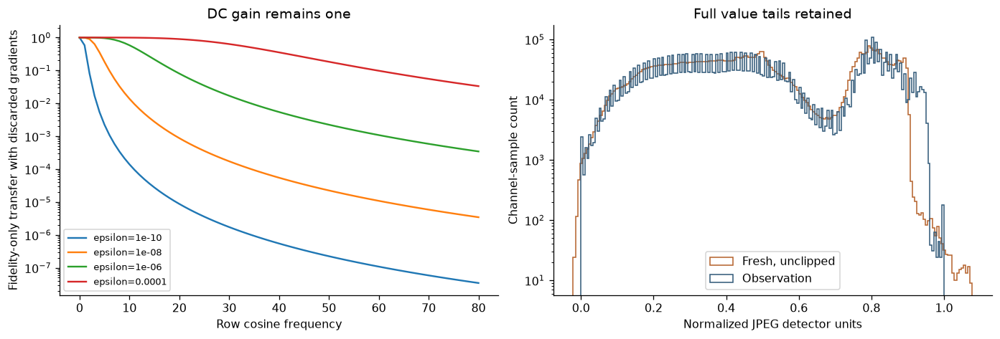

Actual review seconds 90.27146569998877 actual figure groups 11


In [11]:
# Independent modal diagnostic of the constant ambiguity/fidelity term.
frequencies=np.arange(81);kappa=2*(np.cos(np.pi*frequencies/1080)-1)
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for epsilon in epsilons:axes[0].semilogy(frequencies,epsilon/(kappa*kappa+epsilon),label=f'epsilon={epsilon:g}')
axes[0].set_xlabel('Row cosine frequency');axes[0].set_ylabel('Fidelity-only transfer with discarded gradients');axes[0].legend(fontsize=8);axes[0].set_title('DC gain remains one')
axes[1].hist(fresh.ravel(),bins=180,histtype='step',label='Fresh, unclipped',color='#b76732');axes[1].hist(y.ravel(),bins=180,histtype='step',label='Observation',color='#375e7c');axes[1].set_yscale('log');axes[1].set_xlabel('Normalized JPEG detector units');axes[1].set_ylabel('Channel-sample count');axes[1].legend();axes[1].set_title('Full value tails retained');plt.show()
summary={'primary_reconstruction_and_io_seconds':primary_seconds,'judge':report,'retained_gradient_fractions':retained_fraction,'thresholds':h_facts,'epsilon':epsilon_facts,'synthetic':synthetic_facts,'supplementary_real':scene_facts,'gaussian_stress':noise_facts,'review_seconds':time.perf_counter()-started,'truth_status':'No independent actual real-scene transmission truth. Original baseline is labeled conditional method reference.'}
(REF/'fresh_review_metrics.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8');(export/'experiment_summary.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8')
np.savez_compressed(REF/'fresh_cleaned.npz',reconstruction=fresh[None])
print('Actual review seconds',summary['review_seconds'],'actual figure groups',figure_counter)

## 6. Conclusion

The selected full inverse is actively reconstructed, agrees with the independently run original method, and satisfies the discrete variational equation. Threshold, fidelity, noise, independent known-layer and supplementary full-scene experiments reveal its tradeoffs. Solving this equation accurately does not make a single-view decomposition physically unique; low-frequency reflection offsets, focused reflections, weak scene detail and JPEG response remain limitations.

The paper's external Li–Brown, Arvanitopoulos and Wan implementations/results are historical comparisons, not locally executed methods in this selected source package. The notebook does not reproduce their leaderboard or the supplementary video benchmark, and does not fabricate missing output arrays. Selected task-relevant comparisons retain the source gradient/fidelity tradeoff, original/fresh full outputs, real examples and independently known physical cases. Full native arrays remain unclipped; display mapping alone is declared. No actual truth is invented for the real photographs.